# 📚 Word-Level LSTM Language Model: Generating Book Titles

Predicting the next word of book titles from the GoodBooks-10k dataset with an LSTM, then improving both the predictor and the quality of generated titles.

### Highlights
- **Found a data bug:** the original sequence preparation produced 152,000 training examples, of which only 22,556 were unique. Fixing it cut perplexity from **2,529 to 349** on a fair, de-duplicated test set
- **Decoding:** greedy, temperature, and top-k + nucleus sampling
- **Coherent titles:** an end-of-title token, repetition rules, postprocessing and reranking, so that 100% of generated titles end naturally

### Notebook structure
| Part | Topic |
|---|---|
| 1 | Data loading and exploration |
| 2 | Data preparation (tokenization, sequences, padding) |
| 3 | Baseline LSTM model |
| 4 | Inference and evaluation metrics (Top-k accuracy, perplexity, BLEU) |
| 5 | Generation and improvements: 5.1 greedy generation · 5.2 temperature · 5.3 predictor improvements · 5.4 coherent, complete titles |

## Part 1: Data Loading and Initial Exploration

In this section, we load and explore the dataset containing book titles. The key steps performed include:

1. **Loading the Dataset**: The dataset is loaded directly from a URL into a pandas DataFrame.
2. **Basic Information Display**: Basic information about the dataset, including column names and sample data, is displayed.
3. **Title Preprocessing**: Titles are preprocessed by converting them to lowercase and removing non-alphabetic characters.
4. **Title Length Calculation**: The length of each title (in terms of the number of words) is calculated, and basic statistics are displayed.
5. **Visualization**: The distribution of title lengths is plotted using a histogram and box plot, and a word cloud is generated to visualize the most common words in the book titles.


### More on GoodBooks10K Dataset

The **GoodBooks10K** dataset is a comprehensive collection of user ratings, reviews, and metadata for 10,000 books. It is commonly used for recommender systems research and analysis. The dataset includes:

- **Books metadata**: Titles, authors, genres, and publication information.
- **User interactions**: Ratings (1-5 scale) and textual reviews.
- **Additional features**: Tags and user-generated lists.

This dataset provides a rich resource for exploring collaborative filtering, natural language processing, and book-related data analysis.

For more information and to access the dataset, visit the [Kaggle page](https://www.kaggle.com/datasets/zygmunt/goodbooks-10k/).

For insights into advanced recommendation system research, refer to NVIDIA's paper on **Deep Learning-Based Recommender Systems** ([arXiv:1911.12391](https://arxiv.org/pdf/1911.12391)).

Dataset loaded successfully!
Columns: Index(['book_id', 'goodreads_book_id', 'best_book_id', 'work_id',
       'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year',
       'original_title', 'title', 'language_code', 'average_rating',
       'ratings_count', 'work_ratings_count', 'work_text_reviews_count',
       'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5',
       'image_url', 'small_image_url'],
      dtype='object')

Sample Data:
   book_id  goodreads_book_id  best_book_id  work_id  books_count       isbn  \
0        1            2767052       2767052  2792775          272  439023483   
1        2                  3             3  4640799          491  439554934   
2        3              41865         41865  3212258          226  316015849   
3        4               2657          2657  3275794          487   61120081   
4        5               4671          4671   245494         1356  743273567   

         isbn13                      authors 

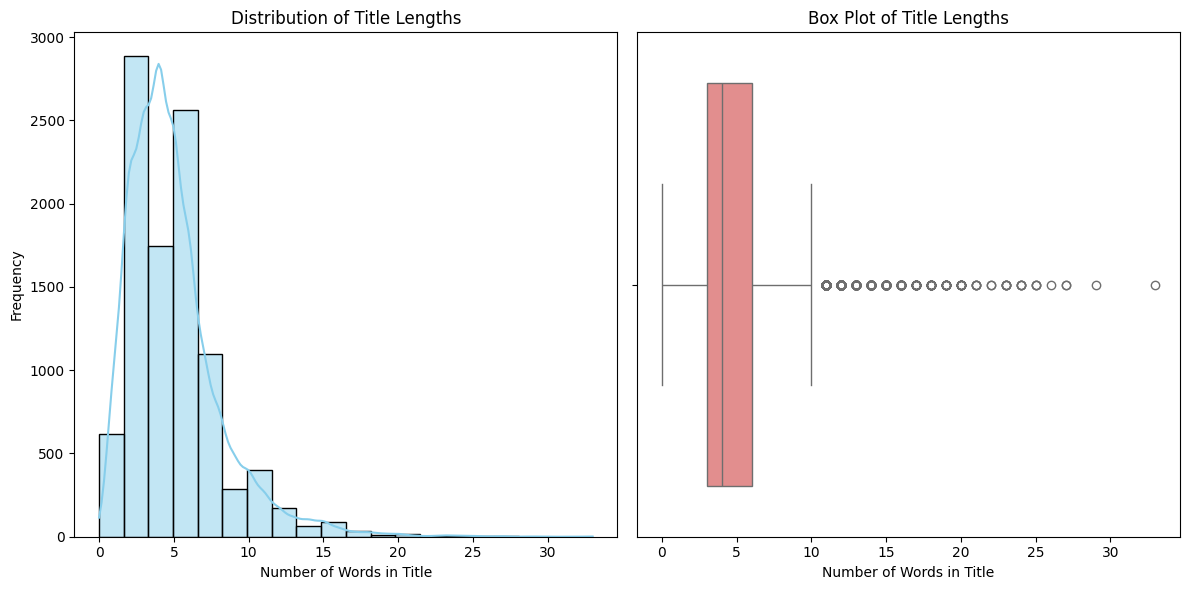

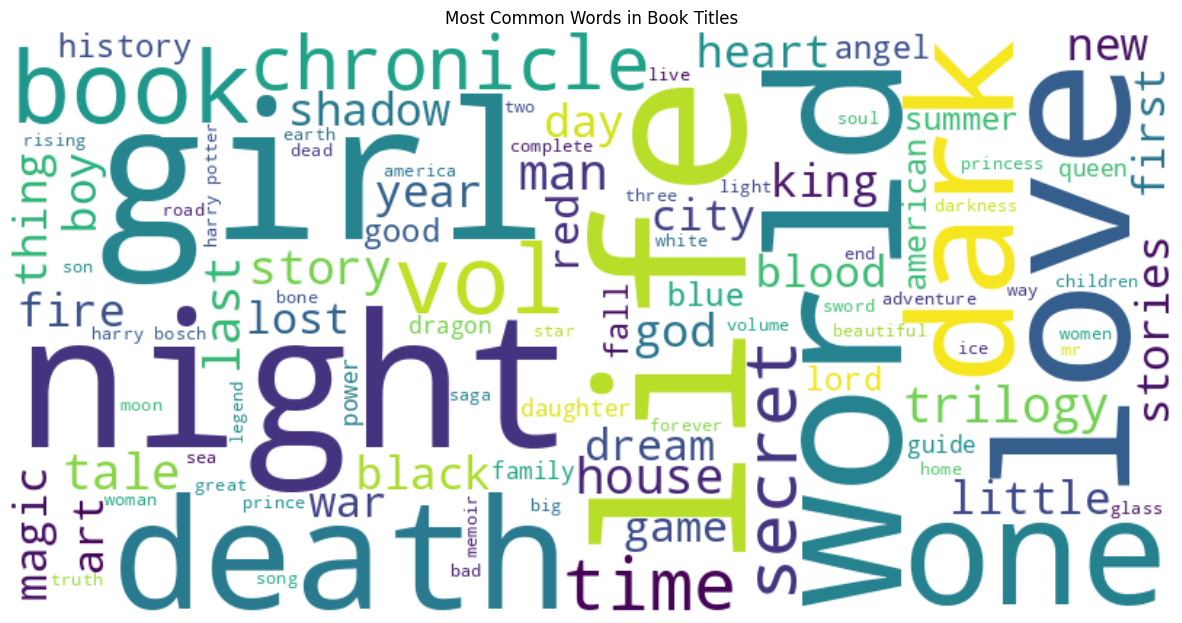

In [ ]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
%pip install seaborn
import seaborn as sns

# URL of the dataset
dataset_url = "https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/books.csv"

# Load the dataset directly into a pandas DataFrame
df = pd.read_csv(dataset_url)

# Display basic information about the dataset
print("Dataset loaded successfully!")
print("Columns:", df.columns)
print("\nSample Data:")
print(df.head())

# Extract titles
titles = df['title']

# Preprocess the titles
def preprocess_title(title):
    title = title.lower()  # Convert to lowercase
    title = ''.join(char if char.isalpha() or char.isspace() else '' for char in title)  # Keep only letters and spaces
    return title

df['cleaned_title'] = titles.apply(preprocess_title)

# Calculate title lengths (number of words)
df['title_length'] = df['cleaned_title'].apply(lambda x: len(x.split()))

# Display statistics
average_length = df['title_length'].mean()
print(f"\nNumber of titles: {len(df)}")
print(f"Average title length: {average_length:.2f} words")
print("\nSample cleaned titles:")
print(df[['title', 'cleaned_title', 'title_length']].head())

# Improved histogram and box plot
plt.figure(figsize=(12, 6))

# Histogram
plt.subplot(1, 2, 1)
sns.histplot(df['title_length'], bins=20, kde=True, color="skyblue", edgecolor='black')
plt.title('Distribution of Title Lengths')
plt.xlabel('Number of Words in Title')
plt.ylabel('Frequency')

# Box plot
plt.subplot(1, 2, 2)
sns.boxplot(x=df['title_length'], color="lightcoral")
plt.title('Box Plot of Title Lengths')
plt.xlabel('Number of Words in Title')

plt.tight_layout()
plt.show()

# Generate a word cloud
all_words = ' '.join(df['cleaned_title'].dropna())
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(all_words)

# Plot the word cloud
plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Book Titles')
plt.show()

## Part 2: Data Preparation

In this section, we prepare the data for training the LSTM-based language model. The key steps performed include:

1. **Tokenizing Text Data**: The text data is tokenized and converted into sequences of numerical values.
2. **Padding Sequences**: The sequences are padded to ensure consistent input size for the model.
3. **Preparing Training and Target Data**: The training and target data are prepared with one-hot encoding for categorical predictions.

The parameters `MAX_WORDS` and `MAX_LENGTH` are defined to restrict the tokenizer to consider only the top 2500 most frequent words and to specify the maximum length of the sequences generated, respectively.

The dataset is split into training and testing sets. The text data is tokenized, and input sequences are created. These sequences are then padded to ensure consistent input size. Finally, the predictors and targets are created, and the target data is one-hot encoded for categorical predictions.

In [ ]:
%pip install tensorflow
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras import utils
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Parameters
MAX_WORDS = 2500  # Limit vocabulary size
MAX_LENGTH = 20    # Max sequence length

# Split the dataset
train_titles, test_titles = train_test_split(df['cleaned_title'].dropna(), test_size=0.2, random_state=42)

# Tokenize and prepare training data
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(train_titles)
train_sequences = tokenizer.texts_to_sequences(train_titles)
test_sequences = tokenizer.texts_to_sequences(test_titles)


# Create sequences for training and testing
def create_sequences(sequences, max_length):
    input_sequences = []
    for sequence in sequences:
        for i in range(1, max_length):
            n_gram_sequence = sequence[:i+1]
            input_sequences.append(n_gram_sequence)
    return input_sequences

# Generate input sequences
train_input_sequences = create_sequences(train_sequences, MAX_LENGTH)
test_input_sequences = create_sequences(test_sequences, MAX_LENGTH)

# Pad sequences
train_padded = pad_sequences(train_input_sequences, maxlen=MAX_LENGTH, padding='pre')
test_padded = pad_sequences(test_input_sequences, maxlen=MAX_LENGTH, padding='pre')

# Create predictors and targets
X_train = train_padded[:, :-1]
y_train = train_padded[:, -1]
X_test = test_padded[:, :-1]
y_test = test_padded[:, -1]

# One-hot encode the target
y_train = utils.to_categorical(y_train, num_classes=MAX_WORDS)
y_test = utils.to_categorical(y_test, num_classes=MAX_WORDS)

print(f'Vocabulary size: {len(tokenizer.word_index)}')
print(f'Number of train sequences: {len(train_input_sequences)}')
print(f'Number of test sequences: {len(test_input_sequences)}')

Vocabulary size: 8260
Number of train sequences: 152000
Number of test sequences: 38000


## Part 3: Model Design and Training
### Baseline LSTM language model

Embedding (100) → LSTM (100) → Dropout (0.2) → LSTM (100) → Dropout (0.2) → Dense (2,500, softmax), trained for 10 epochs with Adam and categorical cross-entropy.

A GPU runtime is recommended (in Colab: **Runtime → Change runtime type → T4 GPU**); training takes about 5–15 minutes depending on hardware.

In [ ]:
import tensorflow as tf

# Check if GPU is available
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout

# Define model
model = Sequential()
model.add(Embedding(input_dim=MAX_WORDS, output_dim=100))
model.add(LSTM(100, return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(100))
model.add(Dropout(0.2))
model.add(Dense(MAX_WORDS, activation='softmax'))

# Compile model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train model
history = model.fit(X_train, y_train, epochs=10, validation_split=0.2, batch_size=48)

Epoch 1/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 38s 11ms/step - accuracy: 0.1116 - loss: 5.9052 - val_accuracy: 0.1382 - val_loss: 6.5818
Epoch 2/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 28s 11ms/step - accuracy: 0.1708 - loss: 4.8958 - val_accuracy: 0.1567 - val_loss: 6.7236
Epoch 3/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 26s 10ms/step - accuracy: 0.2425 - loss: 4.2402 - val_accuracy: 0.1838 - val_loss: 7.0286
Epoch 4/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.3232 - loss: 3.7233 - val_accuracy: 0.2012 - val_loss: 7.4567
Epoch 5/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.4003 - loss: 3.3243 - val_accuracy: 0.2116 - val_loss: 7.9374
Epoch 6/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.4613 - loss: 3.0226 - val_accuracy: 0.2203 - val_loss: 8.3617
Epoch 7/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.5076 - loss: 2.7943 - val_accuracy: 0.2273 - val_loss: 8.7876
Epoch 8/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.5428 -

## Part 4: Inference and Evaluation
### 4.1 Predicting the Next Word and Top-N Words

Two helper functions are defined, `predict_next_word` and `predict_top_n_words`, which are used to predict the next word in a sequence based on a trained language model.

1. **Function: `predict_next_word`**
    - **Input**: Takes a trained model, tokenizer, input text, and maximum sequence length.
    - **Process**:
      - Converts the input text to lowercase.
      - Transforms the text into a sequence of integers using the tokenizer.
      - Pads the sequence to ensure it matches the required input length for the model.
      - Uses the model to predict the next word in the sequence.
      - Finds the word corresponding to the highest predicted probability.
    - **Output**: Returns the predicted next word.

2. **Function: `predict_top_n_words`**
    - **Input**: Takes a trained model, tokenizer, input text, maximum sequence length, and the number of top predictions (`n`).
    - **Process**:
      - Converts the input text to lowercase.
      - Transforms the text into a sequence of integers using the tokenizer.
      - Pads the sequence to ensure it matches the required input length for the model.
      - Uses the model to predict the probabilities of the next word.
      - Retrieves the top `n` words with the highest predicted probabilities.
    - **Output**: Returns a list of tuples containing the top `n` predicted words and their corresponding probabilities.

3. **Testing the Predictions**
    - The code tests the `predict_top_n_words` function with the input text "The perfect book for" and retrieves the top 3 predicted words along with their probabilities.
    - The results are printed in the format: `Word: <word>, Probability: <probability>`.

In [ ]:
import numpy as np

def predict_next_word(model, tokenizer, text, max_length):
    # Preprocess the input text
    text = text.lower()
    sequence = tokenizer.texts_to_sequences([text])[0]
    sequence = pad_sequences([sequence], maxlen=max_length-1, padding='pre')

    # Predict the next word
    predicted = model.predict(sequence, verbose=0)
    predicted_word_index = np.argmax(predicted, axis=-1)[0]

    # Convert the predicted index to word
    for word, index in tokenizer.word_index.items():
        if index == predicted_word_index:
            return word
    return None

def predict_top_n_words(model, tokenizer, text, max_length, n=3):
    # Preprocess the input text
    text = text.lower()
    sequence = tokenizer.texts_to_sequences([text])[0]
    sequence = pad_sequences([sequence], maxlen=max_length-1, padding='pre')

    # Predict the next word probabilities
    predicted = model.predict(sequence, verbose=0)

    # Get the top n predictions
    top_n_indices = np.argsort(predicted[0])[-n:][::-1]
    top_n_predictions = [(tokenizer.index_word[index], predicted[0][index]) for index in top_n_indices]

    return top_n_predictions

# Test predictions
top_predictions = predict_top_n_words(model, tokenizer, 'The perfect book for', MAX_LENGTH, n=3)
for word, prob in top_predictions:
    print(f"Word: {word}, Probability: {prob:.4f}")

Word: the, Probability: 0.2743
Word: love, Probability: 0.0843
Word: women, Probability: 0.0411


### 4.2 Evaluation Metrics for Language Models

To evaluate the performance of our language model, we use the following metrics:

#### a. Top-1 Accuracy
- **Definition**: Measures the percentage of cases where the model's highest-probability prediction matches the correct word.
- **Purpose**: Indicates how often the model predicts the correct word as its first choice.
- **Interpretation**: Higher values mean the model is better at predicting the correct next word directly.

#### b. Top-5 Accuracy
- **Definition**: Measures the percentage of cases where the correct word is among the top 5 predictions made by the model.
- **Purpose**: Evaluates the model's ability to capture the correct word within a small set of candidates.
- **Interpretation**: Useful in applications like auto-suggestions or autocomplete where multiple suggestions are presented.

#### c. Perplexity
- **Definition**: Exponential of the average negative log-likelihood of the predicted probabilities for the correct words.
- **Purpose**: Captures the model's uncertainty; lower perplexity indicates better confidence and alignment with the true distribution.
- **Interpretation**: Lower values are better, as they indicate the model assigns higher probabilities to correct predictions.

#### d. BLEU Score
- **Definition**: A metric for comparing generated sequences to a reference sequence, focusing on n-gram overlap.
- **Purpose**: Evaluates the quality of text generation, often used in tasks like machine translation.
- **Interpretation**: Scores range from 0 to 1, with higher values indicating better alignment between predicted and reference sequences.

#### Why These Metrics?
- **Top-k Accuracy**: Provides a straightforward measure of correctness and relevance of predictions.
- **Perplexity**: Reflects the confidence of the model in its predictions and overall language understanding.
- **BLEU Score**: Assesses how well the generated text matches expected outputs, making it a valuable metric for creative text generation tasks.

These metrics together offer a comprehensive evaluation of the language model's performance across accuracy, confidence, and output quality.


In [ ]:
from sklearn.metrics import accuracy_score
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import numpy as np

def evaluate_model_simple(model, tokenizer, X_test, y_test, max_length, top_k=(1, 5)):
    """
    Evaluate the model on test data using Top-k Accuracy, Perplexity, and BLEU Score.

    Args:
        model: Trained model.
        tokenizer: Fitted tokenizer for converting word indices.
        X_test: Test input data (padded sequences).
        y_test: Test target data (one-hot encoded).
        max_length: Maximum sequence length for padding.
        top_k: Tuple of integers for Top-k accuracy calculations.

    Returns:
        A dictionary with calculated metrics.
    """
    # Convert y_test from one-hot encoding to integer indices
    y_test_indices = np.argmax(y_test, axis=1)

    # Predict probabilities for the test set
    predictions = model.predict(X_test, verbose=0)

    # Create reverse word index
    reverse_word_index = {v: k for k, v in tokenizer.word_index.items()}

    # Top-k Accuracy Calculation
    top_k_accuracies = {}
    for k in top_k:
        top_k_preds = np.argsort(predictions, axis=-1)[:, -k:]
        correct = sum(1 for i in range(len(y_test)) if y_test_indices[i] in top_k_preds[i])
        top_k_accuracies[f"Top-{k} Accuracy"] = correct / len(y_test)

    # Perplexity Calculation
    log_probabilities = -np.log(np.sum(predictions * y_test, axis=1) + 1e-9)
    perplexity = np.exp(np.mean(log_probabilities))

    # BLEU Score Calculation with Smoothing
    bleu_scores = []
    smoothing_function = SmoothingFunction().method1  # Use smoothing function to avoid warnings

    for i in range(len(X_test)):
        reference_word_index = y_test_indices[i]
        predicted_word_index = np.argmax(predictions[i])

        # Skip if indices are not in vocabulary
        if reference_word_index not in reverse_word_index or predicted_word_index not in reverse_word_index:
            continue

        reference_word = [reverse_word_index[reference_word_index]]
        candidate_word = [reverse_word_index[predicted_word_index]]

        # Calculate BLEU score for unigram with smoothing
        bleu_scores.append(sentence_bleu([reference_word], candidate_word, weights=(1, 0, 0, 0), smoothing_function=smoothing_function))
    bleu_score = np.mean(bleu_scores) if bleu_scores else 0.0

    # Combine results into a dictionary
    results = {
        **top_k_accuracies,
        "Perplexity": perplexity,
        "BLEU Score": bleu_score
    }

    return results

# Example usage
results = evaluate_model_simple(model, tokenizer, X_test, y_test, MAX_LENGTH)

# Print results
print("Model Evaluation Metrics:")
for metric, value in results.items():
    print(f"{metric}: {value:.2f}")

Model Evaluation Metrics:
Top-1 Accuracy: 0.25
Top-5 Accuracy: 0.35
Perplexity: 2085.34
BLEU Score: 0.19


## Part 5: Generation and Improvements

### 5.1 Generating Book Titles with the Next-Word Predictor

`generate_text` builds a title one word at a time: it feeds the **full text generated so far** back into the model, picks the most likely next word (greedy decoding), and stops early if the model predicts the padding index. It is tested on several seed phrases, flagging seed words that fall outside the 2,500-word vocabulary.

In [ ]:
def generate_text(model, tokenizer, seed_text, max_length, num_words):
    result = seed_text
    for _ in range(num_words):
        # Preprocess the input text
        sequence = tokenizer.texts_to_sequences([result.lower()])[0]
        sequence = pad_sequences([sequence], maxlen=max_length - 1, padding='pre')

        # Predict the next word and convert to text
        predicted = model.predict(sequence, verbose=0)[0]
        predicted_index = int(np.argmax(predicted))

        # Convert the predicted index to word and add to the result
        next_word = tokenizer.index_word.get(predicted_index)
        if next_word is None:
            break
        result += " " + next_word
    return result
    return result

# Generate 5 words iteratively
seed_text = "The dog"
generated_text = generate_text(model, tokenizer, seed_text, MAX_LENGTH, 5)
print(generated_text)

The dog the testing of amber and


In [ ]:
seeds = ["The system", "In the world of AI", "The secret", "The girl who",
         "A song of", "Harry Potter and the", "Love"]

for seed in seeds:
    unknown = [w for w in seed.lower().split()
               if tokenizer.word_index.get(w) is None or tokenizer.word_index[w] >= MAX_WORDS]
    output = generate_text(model, tokenizer, seed, MAX_LENGTH, 7)
    note = f"   (ignored, not in vocabulary: {unknown})" if unknown else ""
    print(f"{seed!r:<24} -> {output}{note}")

'The system'             -> The system of the worlds man the world in
'In the world of AI'     -> In the world of AI the dark wolves myth trilogy the underworld   (ignored, not in vocabulary: ['ai'])
'The secret'             -> The secret lairds the clues guide to writing the
'The girl who'           -> The girl who beautiful home past past life of us
'A song of'              -> A song of the gang being book club inheritance cycle
'Harry Potter and the'   -> Harry Potter and the the century trilogy the tearling the rings
'Love'                   -> Love the afterlife to the kingdom of french


**Examples of generated titles (7 words each):**
- "The girl who" - *The girl who beautiful home past past life of us*
- "A song of" - *A song of the gang being book club inheritance cycle*
- "The secret" - *The secret lairds the clues guide to writing the*
- "Harry Potter and the" - *Harry Potter and the the century trilogy the tearling the rings*

**Coherence, fluency and quality:**
- **Fluency:** the first 2–3 generated words often sound like a title ("The girl who", "A song of the gang"), but post that outputs lose grammar with a lot of repeats like "the the" and "past past".
- **Coherence:** the outputs have no overall meaning at all. The model puts together pieces of real titles it learned, for example: *inheritance cycle*, *the tearling*, *the rings*, which fits the overfitting during training (59% train vs 23% validation accuracy).
- **Dataset effects:** series words like *trilogy*, *cycle*, *guide* appear often because the cleaned titles still contain series names for example: "Eragon The Inheritance Cycle, #1".
- **No stopping point:** titles were trained without an end-of-title marker so the model never learns when a title is complete and keeps adding words.
- **Unknown words:** seed words outside the 2,500-word vocabulary are ignored.

### 5.2 Temperature Scaling

Temperature controls how random the generated text is. The model's probabilities are rescaled before sampling:
$$
\text{scaled probabilities} = \frac{\exp(\log(\text{probabilities}) / T)}{\sum \exp(\log(\text{probabilities}) / T)}
$$
Low temperatures sharpen the distribution (more focused, more repetitive); high temperatures flatten it (more diverse, more random). The next word is **sampled** from the scaled distribution instead of always taking the most probable one.

Implementation details: probabilities are converted to float64 and renormalized, the maximum is subtracted before `exp` for numerical stability, and the padding index is never sampled.

Tested at T = 0.2, 1.0 and 2.0 on "The perfect book for" plus a more generic and a more specific seed, with a diversity count over 10 generations.

In [ ]:
import numpy as np

def generate_text_with_temperature(model, tokenizer, seed_text, max_length, num_words, temperature=1.0):
    """
    Generate text with temperature scaling for more diverse predictions.

    Args:
        model: Trained language model
        tokenizer: Fitted tokenizer
        seed_text: Initial text to start generation
        max_length: Maximum sequence length
        num_words: Number of words to generate
        temperature: Controls randomness (higher = more random, lower = more deterministic)

    Returns:
        Generated text string
    """

    result = seed_text

    for _ in range(num_words):
        # Preprocess the input text
        sequence = tokenizer.texts_to_sequences([result.lower()])[0]
        sequence = pad_sequences([sequence], maxlen=max_length - 1, padding='pre')

        # Get raw predictions from the model
        probs = model.predict(sequence, verbose=0)[0].astype("float64")
        probs[0] = 0.0

        # Apply temperature scaling
        log_probs = np.log(probs + 1e-12) / temperature  # small value avoids log(0)
        log_probs -= np.max(log_probs)                   # numerical stability (no overflow in exp)
        scaled_probs = np.exp(log_probs)
        scaled_probs /= np.sum(scaled_probs)

        # Sample from the scaled distribution to get the predicted index
        predicted_index = np.random.choice(len(probs), p=scaled_probs)

        # Convert the predicted index to word and add to the result
        next_word = tokenizer.index_word.get(predicted_index)
        if next_word is None:
            break
        result += " " + next_word

    return result

# Test with different temperatures
seed_text = "The perfect book for"
print("Temperature = 0.2 (More focused):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=0.2))
print("\nTemperature = 1.0 (Balanced):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=1.0))
print("\nTemperature = 2.0 (More diverse):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=2.0))

Temperature = 0.2 (More focused):
The perfect book for the underworld beauty beauty darkness

Temperature = 1.0 (Balanced):
The perfect book for vol mary london covenant and

Temperature = 2.0 (More diverse):
The perfect book for rise very neglected history and


In [ ]:
np.random.seed(42)   # reproducible sampling

seeds = ["The perfect book for",   # required seed
         "The lion",                    # more generic
         "The girl who"]           # more specific
temperatures = [0.2, 1.0, 2.0]

for seed in seeds:
    print(f"\n{'=' * 70}\nSeed: '{seed}'\n{'=' * 70}")
    for T in temperatures:
        print(f"\n  Temperature = {T}:")
        for _ in range(3):
            print("   ", generate_text_with_temperature(model, tokenizer, seed, MAX_LENGTH, 7, temperature=T))

# How diverse is each temperature? (10 generations each)
print(f"\n{'=' * 70}\nDiversity: distinct outputs out of 10 ('The perfect book for', 7 words)\n{'=' * 70}")
for T in temperatures:
    outputs = [generate_text_with_temperature(model, tokenizer, "The perfect book for", MAX_LENGTH, 7, temperature=T)
               for _ in range(10)]
    print(f"  T = {T}: {len(set(outputs))}/10 distinct")


Seed: 'The perfect book for'

  Temperature = 0.2:
    The perfect book for the underworld days in america wisdom of
    The perfect book for the underworld days the walking dead the
    The perfect book for the underworld vampire chronicles crossover business business

  Temperature = 1.0:
    The perfect book for the dragon chronicles and fates of space
    The perfect book for things love in america universe shoes bride
    The perfect book for boxed set the angel school bear before

  Temperature = 2.0:
    The perfect book for the evening we faith tales complete tell
    The perfect book for an effective purpose amos hyde novel germany
    The perfect book for for man for god when are they

Seed: 'The lion'

  Temperature = 0.2:
    The lion of fear of earth and thorns america
    The lion of fear of earth and thorns america
    The lion of fear of earth and thorns the

  Temperature = 1.0:
    The lion of fear and poems of in and
    The lion and damned fire hard can be you
    

**Example outputs (seed → generated, 7 words):**

| Temperature | "The perfect book for" | "The lion" | "The girl who" |
|---|---|---|---|
| 0.2 | ...the underworld days the walking dead the | ...of fear of earth and thorns america | ...beautiful home past past life of us |
| 1.0 | ...the dragon chronicles and fates of space | ...the king of old world of reason | ...forever a time disney two little girls |
| 2.0 | ...for man for god when are they | ...trouble wish year them right be religion | ...cooks doyle not ii away chance volume |

**Effect of temperature:**
- **Low (0.2):** very focused and repetitive. "The lion" produced nearly the same output three times, and "The girl who" exactly matched the greedy output from 5.1, including the repeated "past past".
- **Medium (1.0):** a different output every time, with short title-like phrases ("the dragon chronicles", "two little girls"), many of them fragments of real titles ("vampire chronicles", "the walking dead"). This gave the best balance between variety and readability.
- **High (2.0):** grammar breaks down ("for man for god when are they") and rare words appear much more often, since high temperature makes all words nearly equally likely.
- **Diversity:** out of 10 generations, 7, 10 and 10 were distinct for T = 0.2, 1.0 and 2.0. Uniqueness already saturates at 1.0, so the difference between 1.0 and 2.0 shows up in coherence rather than variety.

**Takeaway:** temperature trades coherence for diversity, but it cannot make a weak model good. Since the model only reaches 23% validation accuracy, low temperatures give consistent but repetitive text and high temperatures give varied but random text; none of the settings produce truly meaningful titles.

### 5.3 Improving the Next-Word Predictor

**Goal:** meaningful, incremental improvements to the data preparation, model architecture or training, without additional training data or pretrained language models.

All versions are evaluated with Top-1 accuracy, Top-5 accuracy, BLEU and perplexity, and compared with the baseline on the **same clean test set**.

In [ ]:
# 5.3 Improving the next-word predictor
import tensorflow as tf
from keras.callbacks import EarlyStopping

#Change 1: one example per prefix
def create_clean_sequences(sequences):
    out = []
    for seq in sequences:
        for i in range(1, len(seq)):
            out.append(seq[:i + 1])
    return out

train_clean = pad_sequences(create_clean_sequences(train_sequences), maxlen=MAX_LENGTH, padding='pre')
test_clean  = pad_sequences(create_clean_sequences(test_sequences),  maxlen=MAX_LENGTH, padding='pre')

X_train_c, y_train_c = train_clean[:, :-1], train_clean[:, -1]                  # integer targets
X_test_c  = test_clean[:, :-1]
y_test_c  = utils.to_categorical(test_clean[:, -1], num_classes=MAX_WORDS)       # one-hot, for evaluate_model_simple

n_unique = len(np.unique(train_padded, axis=0))
print(f"Original train sequences: {len(train_padded):,} (only {n_unique:,} unique)")
print(f"Clean train sequences:    {len(X_train_c):,}")
print(f"Clean test sequences:     {len(X_test_c):,}")

# Re-evaluating the ORIGINAL baseline on the clean test set
results_baseline_clean = evaluate_model_simple(model, tokenizer, X_test_c, y_test_c, MAX_LENGTH)
print("\nBaseline on clean test set:", {k: round(v, 3) for k, v in results_baseline_clean.items()})

Original train sequences: 152,000 (only 22,556 unique)
Clean train sequences:    25,493
Clean test sequences:     5,849

Baseline on clean test set: {'Top-1 Accuracy': 0.133, 'Top-5 Accuracy': 0.243, 'Perplexity': np.float64(2529.32), 'BLEU Score': np.float64(0.133)}


In [ ]:
def build_lm(mask_zero=False, dropout=0.2):
    cudnn = False if mask_zero else "auto"
    m = Sequential([
        Embedding(input_dim=MAX_WORDS, output_dim=100, mask_zero=mask_zero),  # Change 2: mask padding
        LSTM(100, return_sequences=True, use_cudnn=cudnn),
        Dropout(dropout),
        LSTM(100,use_cudnn=cudnn),
        Dropout(dropout),
        Dense(MAX_WORDS, activation='softmax'),
    ])
    # sparse = integer targets instead of one-hot: same loss, far less memory
    m.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return m

#  Version 1: clean data
tf.keras.utils.set_random_seed(42)
model_v1 = build_lm()
history_v1 = model_v1.fit(X_train_c, y_train_c, epochs=10, validation_split=0.2, batch_size=48, verbose=2)
results_v1 = evaluate_model_simple(model_v1, tokenizer, X_test_c, y_test_c, MAX_LENGTH)

# version 2: + masking, dropout 0.3, early stopping (Change 3)
tf.keras.utils.set_random_seed(42)
model_v2 = build_lm(mask_zero=True, dropout=0.3)
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
history_v2 = model_v2.fit(X_train_c, y_train_c, epochs=20, validation_split=0.2, batch_size=48,
                          callbacks=[early_stop], verbose=2)
results_v2 = evaluate_model_simple(model_v2, tokenizer, X_test_c, y_test_c, MAX_LENGTH)

Epoch 1/10
425/425 - 6s - 14ms/step - accuracy: 0.0861 - loss: 6.6327 - val_accuracy: 0.1090 - val_loss: 6.4545
Epoch 2/10
425/425 - 4s - 9ms/step - accuracy: 0.1108 - loss: 6.3043 - val_accuracy: 0.1234 - val_loss: 6.4019
Epoch 3/10
425/425 - 5s - 12ms/step - accuracy: 0.1205 - loss: 6.1755 - val_accuracy: 0.1312 - val_loss: 6.3214
Epoch 4/10
425/425 - 4s - 9ms/step - accuracy: 0.1305 - loss: 6.0327 - val_accuracy: 0.1365 - val_loss: 6.2588
Epoch 5/10
425/425 - 4s - 9ms/step - accuracy: 0.1370 - loss: 5.9075 - val_accuracy: 0.1390 - val_loss: 6.2457
Epoch 6/10
425/425 - 6s - 15ms/step - accuracy: 0.1406 - loss: 5.8035 - val_accuracy: 0.1371 - val_loss: 6.2291
Epoch 7/10
425/425 - 5s - 12ms/step - accuracy: 0.1430 - loss: 5.7107 - val_accuracy: 0.1392 - val_loss: 6.2290
Epoch 8/10
425/425 - 4s - 10ms/step - accuracy: 0.1458 - loss: 5.6129 - val_accuracy: 0.1416 - val_loss: 6.2373
Epoch 9/10
425/425 - 4s - 9ms/step - accuracy: 0.1471 - loss: 5.5247 - val_accuracy: 0.1438 - val_loss: 6.2

                                    Top-1 Accuracy  Top-5 Accuracy  \
Baseline (original test)                     0.248           0.349   
Baseline (clean test)                        0.133           0.243   
V1: clean data                               0.144           0.261   
V2: + masking, dropout, early stop           0.152           0.277   

                                    Perplexity  BLEU Score  
Baseline (original test)              2085.337       0.191  
Baseline (clean test)                 2529.320       0.133  
V1: clean data                         357.346       0.144  
V2: + masking, dropout, early stop     348.583       0.152  

Reference: perplexity of random guessing over 2,500 words = 2,500


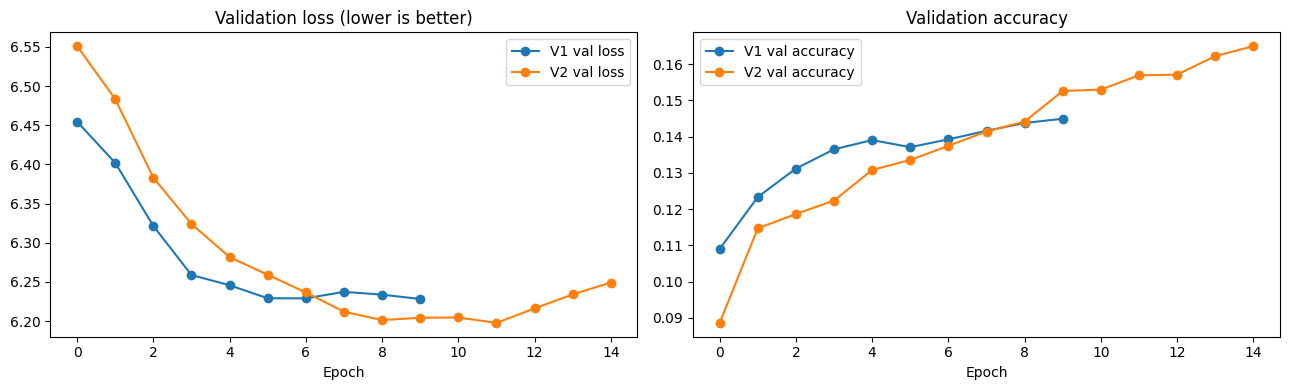

In [ ]:
comparison = pd.DataFrame({
    "Baseline (original test)":            results,
    "Baseline (clean test)":               results_baseline_clean,
    "V1: clean data":                      results_v1,
    "V2: + masking, dropout, early stop":  results_v2,
}).T
print(comparison.round(3))
print("\nReference: perplexity of random guessing over 2,500 words = 2,500")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in [("V1", history_v1), ("V2", history_v2)]:
    axes[0].plot(h.history['val_loss'], marker='o', label=f"{name} val loss")
    axes[1].plot(h.history['val_accuracy'], marker='o', label=f"{name} val accuracy")
axes[0].set_title("Validation loss (lower is better)"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

### 5.3 Results

**Changes made (each targets a problem found in the baseline):**
1. **Data: removed duplicate sequences.** The original `create_sequences` always loops 19 times, so short titles produce the same final example many times. Only 22,556 of the 152,000 training sequences were unique. The new version creates exactly one example per prefix (25,493 sequences).
2. **Architecture: masking.** Titles average ~5 words but are padded to 19. `Embedding(mask_zero=True)` makes the LSTM skip the padding instead of processing it.
3. **Training: regularization.** The baseline's validation loss rose every epoch (6.58 → 9.71), a clear sign of overfitting. Dropout was raised to 0.3, and early stopping keeps the epoch with the lowest validation loss.

To compare fairly, all models were evaluated on the same **clean test set** (one example per prefix), including the original baseline.

| Model | Top-1 | Top-5 | Perplexity | BLEU |
|---|---|---|---|---|
| Baseline (original test) | 0.248 | 0.349 | 2085 | 0.191 |
| Baseline (clean test) | 0.133 | 0.243 | 2529 | 0.133 |
| V1: clean data | 0.144 | 0.261 | 357 | 0.144 |
| V2: + masking, dropout, early stopping | **0.152** | **0.277** | **349** | **0.152** |

**Discussion:**
- **The baseline's metrics were inflated by duplicates.** On clean data its Top-1 accuracy halves (0.248 → 0.133), and its perplexity (2,529) is worse than random guessing over 2,500 words.
- **Removing duplicates gave the biggest gain:** perplexity dropped about 7× (2,529 → 357), and validation loss now decreases during training instead of rising.
- **Masking and regularization added a smaller but consistent gain** on every metric, with Top-5 accuracy reaching 27.7%.
- **Early stopping trade-off:** validation accuracy kept rising slightly after the best-loss epoch, but loss was used for selection since it directly determines perplexity.
- **BLEU equals Top-1 on clean data**, because for single-word predictions BLEU is just an exact-match score.
- **Why accuracy stays modest:** predicting the next word of a book title is hard. Titles are short and creative, and with only ~6,400 training titles, many next words are genuinely unpredictable.

### 5.4 Coherent and Complete Titles

The greedy and temperature-based generators produce run-on, repetitive or incoherent titles. This section addresses that with:
- **End-of-title token:** the model is retrained with a special token after every title, and generation stops when it is predicted
- **Heuristics:** no repeated content words and no immediate word repeats
- **Diversity-controlled sampling:** top-k + nucleus (top-p) sampling
- **Postprocessing and reranking:** trim dangling function words and keep the most probable of several candidates

Titles are compared before and after on the same seed phrases.

In [ ]:
# 5.4 Model with an end-of-title token
import string

END_TOKEN = "xxend"

train_titles_eos = [t + " " + END_TOKEN for t in train_titles]
tokenizer_eos = Tokenizer(num_words=MAX_WORDS)
tokenizer_eos.fit_on_texts(train_titles_eos)
print(f"'{END_TOKEN}' index: {tokenizer_eos.word_index[END_TOKEN]} (must be < {MAX_WORDS})")

train_eos = pad_sequences(create_clean_sequences(tokenizer_eos.texts_to_sequences(train_titles_eos)),
                          maxlen=MAX_LENGTH, padding='pre')
X_train_eos, y_train_eos = train_eos[:, :-1], train_eos[:, -1]

tf.keras.utils.set_random_seed(42)
model_eos = build_lm(mask_zero=True, dropout=0.3)
model_eos.fit(X_train_eos, y_train_eos, epochs=20, validation_split=0.2, batch_size=48,
              callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)],
              verbose=2)

'xxend' index: 1 (must be < 2500)
Epoch 1/20
549/549 - 17s - 32ms/step - accuracy: 0.2247 - loss: 5.8886 - val_accuracy: 0.2267 - val_loss: 5.5615
Epoch 2/20
549/549 - 4s - 8ms/step - accuracy: 0.2251 - loss: 5.4068 - val_accuracy: 0.2264 - val_loss: 5.5047
Epoch 3/20
549/549 - 5s - 8ms/step - accuracy: 0.2192 - loss: 5.2876 - val_accuracy: 0.2174 - val_loss: 5.4389
Epoch 4/20
549/549 - 4s - 7ms/step - accuracy: 0.2274 - loss: 5.1840 - val_accuracy: 0.2426 - val_loss: 5.3875
Epoch 5/20
549/549 - 4s - 7ms/step - accuracy: 0.2407 - loss: 5.0838 - val_accuracy: 0.2498 - val_loss: 5.3483
Epoch 6/20
549/549 - 4s - 7ms/step - accuracy: 0.2477 - loss: 4.9877 - val_accuracy: 0.2533 - val_loss: 5.3241
Epoch 7/20
549/549 - 4s - 7ms/step - accuracy: 0.2524 - loss: 4.8901 - val_accuracy: 0.2589 - val_loss: 5.3215
Epoch 8/20
549/549 - 4s - 7ms/step - accuracy: 0.2592 - loss: 4.7902 - val_accuracy: 0.2621 - val_loss: 5.3235
Epoch 9/20
549/549 - 4s - 7ms/step - accuracy: 0.2638 - loss: 4.6963 - val_a

In [ ]:
FUNCTION_WORDS = {"the", "of", "and", "a", "an", "in", "to", "for", "on", "at", "with", "from", "by", "or", "is"}

def generate_title(model, tokenizer, seed_text, max_length, max_words=8,
                   temperature=0.8, top_k=20, top_p=0.9, min_words=2):
    end_idx = tokenizer.word_index[END_TOKEN]
    seed_words = seed_text.lower().split()
    words, log_probs, ended = list(seed_words), [], False

    for step in range(max_words):
        seq = pad_sequences(tokenizer.texts_to_sequences([" ".join(words)]), maxlen=max_length - 1, padding='pre')
        original = model(seq, training=False).numpy()[0].astype("float64")
        probs = original.copy()
        probs[0] = 0.0                                          # padding is not a word

        # Heuristic: no repeated content words, never the same word twice in a row
        for w in set(words):
            idx = tokenizer.word_index.get(w)
            if idx is not None and idx < MAX_WORDS and (w not in FUNCTION_WORDS or w == words[-1]):
                probs[idx] = 0.0
        if step < min_words:                                    # don't end before 2 new words
            probs[end_idx] = 0.0

        # Temperature, then top-k + nucleus (top-p) sampling
        logits = np.log(probs + 1e-12) / temperature
        p = np.exp(logits - logits.max()); p /= p.sum()
        top = np.argsort(p)[::-1][:top_k]                       # k most likely words
        keep = top[:np.searchsorted(np.cumsum(p[top]), top_p) + 1]   # covering 90% of probability
        idx = int(np.random.choice(keep, p=p[keep] / p[keep].sum()))

        log_probs.append(np.log(original[idx] + 1e-12))         # model's own confidence in this word
        if idx == end_idx:                                      # End-token strategy: stop here
            ended = True
            break
        words.append(tokenizer.index_word[idx])

    # Postprocessing: trim dangling function words, title-case the result
    generated = words[len(seed_words):]
    while generated and generated[-1] in FUNCTION_WORDS:
        generated.pop()
    title = string.capwords(" ".join([seed_text.lower()] + generated))
    return {"title": title, "ended": ended, "score": float(np.mean(log_probs))}

def best_title(model, tokenizer, seed_text, max_length, n_candidates=8, **kwargs):
    """Reranking: generate several candidates, keep the most probable one that ended naturally."""
    candidates = [generate_title(model, tokenizer, seed_text, max_length, **kwargs) for _ in range(n_candidates)]
    return max(candidates, key=lambda c: (c["ended"], c["score"]))

In [ ]:
np.random.seed(0)
seeds = ["The perfect book for", "The girl who", "The lion", "A song of",
         "The secret", "Love", "Harry Potter and the", "The dog"]

for seed in seeds:
    before = generate_text(model, tokenizer, seed, MAX_LENGTH, 7)   # 5.1: baseline + greedy
    after = best_title(model_eos, tokenizer_eos, seed, MAX_LENGTH)
    print(f"\nSeed: '{seed}'\n  Before: {before}\n  After:  {after['title']}"
          f"{'' if after['ended'] else '   (hit length limit)'}")

# Simple quality stats over 5 generations per seed
def repeated_content(t):
    w = [x for x in t.lower().split() if x not in FUNCTION_WORDS]
    return len(w) != len(set(w))

def dangling_end(t):
    return t.lower().split()[-1] in FUNCTION_WORDS

before_T1 = [generate_text_with_temperature(model, tokenizer, s, MAX_LENGTH, 7, temperature=1.0)
             for s in seeds for _ in range(5)]
after_runs = [best_title(model_eos, tokenizer_eos, s, MAX_LENGTH) for s in seeds for _ in range(5)]
after_titles = [r["title"] for r in after_runs]

print(f"\n{'':<28}{'Before (T=1.0)':>16}{'After':>10}")
print(f"{'Repeated content words':<28}{np.mean([repeated_content(t) for t in before_T1]):>15.0%}"
      f"{np.mean([repeated_content(t) for t in after_titles]):>10.0%}")
print(f"{'Ends on the/of/and...':<28}{np.mean([dangling_end(t) for t in before_T1]):>15.0%}"
      f"{np.mean([dangling_end(t) for t in after_titles]):>10.0%}")
print(f"{'Ended naturally (end token)':<28}{'n/a':>16}{np.mean([r['ended'] for r in after_runs]):>10.0%}")


Seed: 'The perfect book for'
  Before: The perfect book for the underworld the world in miracles ashes
  After:  The Perfect Book For The History Of The Life

Seed: 'The girl who'
  Before: The girl who beautiful home past past life of us
  After:  The Girl Who The World Of The Life

Seed: 'The lion'
  Before: The lion of fear of earth and thorns america
  After:  The Lion

Seed: 'A song of'
  Before: A song of the gang being book club inheritance cycle
  After:  A Song Of The Art Of Death

Seed: 'The secret'
  Before: The secret lairds the clues guide to writing the
  After:  The Secret Of The Book

Seed: 'Love'
  Before: Love the afterlife to the kingdom of french
  After:  Love Of The Dark

Seed: 'Harry Potter and the'
  Before: Harry Potter and the the century trilogy the tearling the rings
  After:  Harry Potter And The Chronicles Of The World

Seed: 'The dog'
  Before: The dog the testing of amber and the world
  After:  The Dog

                              Before (T=1.0)     

### 5.4 Results

**Problems found in the original generation (5.1/5.2):** titles never stopped (no end marker), words repeated ("past past", "the the"), titles ended mid-phrase ("...the wisdom of"), and sampling was either too repetitive (low temperature) or too random (high temperature).

**Strategies implemented:**
1. **End token:** retrained the model (V2 setup) with a special word `xxend` after every title, and generation stops when it is predicted.
2. **Heuristics:** content words cannot repeat, and no word can appear twice in a row.
3. **Top-k + nucleus sampling:** sample only from the 20 most likely words that together cover 90% of the probability (temperature 0.8), to avoid both extremes seen in 5.2.
4. **Postprocessing:** trim dangling function words at the end (the/of/and...) and title-case the output.
5. **Reranking:** generate 8 candidates and keep the most probable one that ended naturally.

**Before vs after:**

| Seed | Before (greedy, 5.1) | After |
|---|---|---|
| A song of | A song of the gang being book club inheritance cycle | A Song Of The Art Of Death |
| The secret | The secret lairds the clues guide to writing the | The Secret Of The Book |
| Love | Love the afterlife to the kingdom of french | Love Of The Dark |
| The girl who | The girl who beautiful home past past life of us | The Girl Who The World Of The Life |
| The lion | The lion of fear of earth and thorns america | The Lion |

| | Before (T=1.0) | After |
|---|---|---|
| Repeated content words | 8% | 0% |
| Ends on the/of/and | 28% | 0% |
| Ended naturally (end token) | n/a | 100% |

**Analysis:**
- **Completion improved clearly:** every title ended on its own, showing the model learned where titles finish. Outputs now follow common title patterns like "The X of the Y". (The 0% repeat and dangling-ending rates are guaranteed by the rules; the "before" column shows how common those problems were.)
- **Trade-off: titles became generic.** Phrases like "of the", "the world" and "the life" appear across different seeds, because reranking favors the most probable, safest words. Coherence improved at the cost of creativity.
- **Remaining issues:** grammar still breaks at times ("The Girl Who The World..."), since the model only tracks a few previous words, and some seeds ("The Lion") got no new words because the generated phrase consisted only of trimmed function words.
- **Possible next steps:** rerank with less weight on probability to keep more variety, or require at least one new content word per title.